# Foundation Models for Forecasting

**In this notebook**

1. [What is a foundation model?](#fm-what) - concepts, and what to watch out for in practice
2. [Foundation models in `sktime`](#fm-sktime) - many FMs behind one API: zero-shot forecasts, model code, hierarchical and probabilistic forecasts
3. [Fine-tuning on your data](#fm-finetune) - `pretrain` adapts the provider's weights to your own series
4. [Legal side and methodology](#fm-legal) - licenses, and should I use FMs at all?
5. [Recap](#fm-recap) - what we learnt

In [1]:
import warnings

warnings.filterwarnings("ignore")

<a id="fm-what"></a>
## 1. What is a foundation model?

**Now:** what a foundation model is, how it relates to global forecasting and pretraining from the last notebook,
and the vocabulary: open vs. gated, zero-shot vs. fine-tuning.

foundation model (FM) = **pre-trained models** that perform well on a wider range of data

"forecasting FM" = for the task of uni/multivariate forecasting

typically (but not necessarily) uses "transformer" or other advanced deep learning architecture

**how FM are typically used:**

1. provider trains model on large amount of data (secret/closed)
2. weights and code put online on marketplace (e.g., huggingface, replicate)
3. user forecasts using weights on their data

<img src="./imgs/global-fcst.png" alt="Global Forecast" style="width: 100%; max-width: 600px;">

**pre-trained model above typically from weight repository**

* "semi-open model" - weights can be downloaded and used with open code
* "gated model" - weights not accessible, only gated API (paid service subscription)

pre-trained on batches that are:
* typically large
* across various domains
* *not accessible to the end user*

**learning tasks**

* "originally": language prompting and generative language tasks
* forecasting: typically, univariate or multivariate forecasting
* other time series tasks may be supported but are rare

**relation to global forecasting**:

FM vanilla use are a form of "global forecasting" where:

* "global training" is done by the provider
* trained model provided as weights (download or gated)
* usage: "global prediction/inference" based on these weights

same principle! difference = "trained model handling"

* classical global forecasting = user trains on their own data, often small/mid size
* "foundation models" = model provider trains on large secret batch, shares only weights

**zero-shot, few-shot, and fine-tuning**

* **zero-shot** = model does no training on user data, just "ingests" as "context"
* **few-shot** = model can be trained on user data samples to improve. Core model weights do not change.
* **fine-tuning** = adapting core model weights to user data, e.g., via LoRA, PEFT

**schematic overview weight flow diagram for semi-open model**

<img src="./imgs/FM conceptual.jpg" style="width: 100%; max-width: 600px;">

**gated model: weights are not downloadable but gated behind paywall**

**"degrees of openness"**

| Component                        | Commonly (2024–2025 Trend)    | Caveats |
|----------------------------------|--------------------------------------------|----------|
| Model Weights                    | ✅❌ Varies! Gated vs open | Lots of propaganda by providers |
| Inference Code                   | ✅❌ Varies! Gated vs open | usually open iff weights are |
| Model Architecture               | ✅ Mostly Open | visible for non-gated models |
| Training Code                    | ❌ Mostly Closed | "reveals" may be strategic, e.g., DeepSeek |
| Training Data                    | ❌ Mostly Closed | might involve public benchmarks |
| Data Collection Methodology      | ❌ Omitted or Vague | likely massive IP violations |
| Evaluation Benchmarks Used       | ✅ Often Open | propaganda - every model is "1st" |
| Fine-tuning Recipes              | ✅❌ Varies! Gated vs open | "gated fine-tuning" as model |
| License Information            | ✅❌ Varies. | stealth changes possible! |

capabilities and properties:

* "degrees of openness" (see above)
* learning task - univariate, multivariate forecasting; other time series tasks
* capability zero-shot, few-shot, fine-tune

### Time series foundation models in practice

**Next:** what to watch out for before using one.

Users should be aware of three dimensions:

* **methodological abstractions** - e.g., which task, how to test/benchmark
* **software & artefact handling** - e.g., library, weights, APIs
* **commercial & legal** - e.g., "lock-in", contracts, licenses

**High-level caveats - methodological**

lots of commercial propaganda...

* every model is 1st on some leaderboard
* pre-training batch is secret, could have contained public benchmark data
* massive influencer campaigns on social media and via academia (!)
* marketing claims may or may not hold up to scrutiny

Models may or may not work on your data!

**IMPORTANT: need to benchmark models on your own data**

will revisit below.

**High-level caveats - commercial & legal**

* gated models as core business model of companies! e.g., Nixtla, Prior labs
* models of equivalent performance may be available semi-open or fully open

Do the pros/cons - consider trade-offs, e.g.

* costs (running/initial)
* legal liabilities, licenses
* data protection, control of IP relevant content!

will revisit below.

**High-level caveats - software/artefacts**

2026 state: model code not easily installable!

* many models have no proper package releases (tendency increasing)
* heavy or conflicted dependency sets
* highly inconsistent API
* often intentional push to user "lock-in" or "lock-down", esp gated

will revisit below.

**What we learnt so far**

* foundation model = deep learning model pretrained by a provider on large (secret) data - you get the weights, or a gated API
* use zero-shot, or adapt to your data via few-shot / fine-tuning
* caveats: marketing claims, hard-to-install code, changing licenses - **benchmark on your own data**

**Next:** how `sktime` handles these models for you.

<a id="fm-sktime"></a>
## 2. Foundation models in `sktime`

**Now:** how `sktime` puts many foundation models behind one consistent API -
then zero-shot forecasts, managing model code, and hierarchical / probabilistic forecasts.

`sktime` is the only framework where you can get these in a single place!

In [ ]:
from sktime.registry import all_estimators

fms = all_estimators(
    "forecaster",
    filter_tags={"category": "foundation_model"},
    return_tags=["capability:pretrain", "capability:pred_int", "capability:exogenous"],
    as_dataframe=True,
)
print(f"{len(fms)} foundation model forecasters in sktime")

W1120 19:35:06.142000 44952 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


34 foundation model forecasters in sktime


,name,capability:pretrain,capability:pred_int,capability:exogenous
0,AuroraForecaster,None,True,False
1,Chronos2Forecaster,None,False,True
2,ChronosForecaster,None,False,False
3,CiscoTSMForecaster,None,True,False
4,FalconTSTForecaster,None,False,False
5,FalconXForecaster,None,True,False
6,FlowStateForecaster,None,True,False
7,KronosForecaster,False,False,False
8,LagLlamaForecaster,True,True,False
9,MIRAForecaster,None,False,False


without `sktime`, highly inconsistent APIs, compare:

**Moirai**
```
model = MoiraiForecast(
    module=MoiraiModule.from_pretrained(f"Salesforce/moirai-1.0-R-small"),
    prediction_length=prediction_length,
    context_length=context_length,
    patch_size=patch_size,
    num_samples=100,
    target_dim=1,
    feat_dynamic_real_dim=ds.num_feat_dynamic_real,
    past_feat_dynamic_real_dim=ds.num_past_feat_dynamic_real,
)

predictor = model.create_predictor(batch_size=batch_size)
forecasts = predictor.predict(test_data.input)
```

**TinyTimeMixer**
```
model, _ = TinyTimeMixerForPrediction.from_pretrained(
    model_path,
    revision=revision,
    config=config,
    output_loading_info=True,
    ignore_mismatched_sizes=True,
)

outputs = model(
    past_values=past_values,
    observed_mask=observed_mask,
)
```

`sktime`-less users need to manage:
* **model code**, e.g., source installation
* **model code dependencies**, python packages
* **weights**, e.g., .pkl, .pt, .bin, .h5 files
* **weight dependencies**, python packages

`sktime` is **the only package** that provides access to many FM under single interface.

**users first**, **sovereignty** and **neutrality** mission.

`sktime` API abstracts this away and manages on framework level

<img src="./imgs/fm-simple.png" alt="Foundation Model Overview" style="width: 100%; max-width: 600px;">

**Now:** FMs in action - zero-shot forecasts with TinyTimeMixer and TimesFM on the airline data, then a quick comparison against a simple baseline.

In [3]:
from sktime.datasets import load_airline

# Load the dataset for example
y = load_airline()

# DL models need to set a prediction length (same as simpler DL models)
pred_len = 16

#### Example: TinyTimeMixer

- **Research Paper:** [Tiny Time Mixers (TTMs): Fast Pre-trained Models for Enhanced Zero/Few-Shot Forecasting of Multivariate Time Series](https://www.researchgate.net/profile/Vijay-Ekambaram/publication/381111250_Tiny_Time_Mixers_TTMs_Fast_Pre-trained_Models_for_Enhanced_ZeroFew-Shot_Forecasting_of_Multivariate_Time_Series/links/665d8c5d0b0d2845747de5f5/Tiny-Time-Mixers-TTMs-Fast-Pre-trained-Models-for-Enhanced-Zero-Few-Shot-Forecasting-of-Multivariate-Time-Series.pdf)
- **Official Code:** [ibm-granite/granite-tsfm](https://github.com/ibm-granite/granite-tsfm)

In [4]:
from sktime.forecasting.ttm import TinyTimeMixerForecaster

**Zero-Shot Forecasting**

with the default configuration, model performs zero-shot

In [5]:
forecaster = TinyTimeMixerForecaster()

forecaster.fit(y, fh=list(range(1, pred_len+1)))
y_pred = forecaster.predict()

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

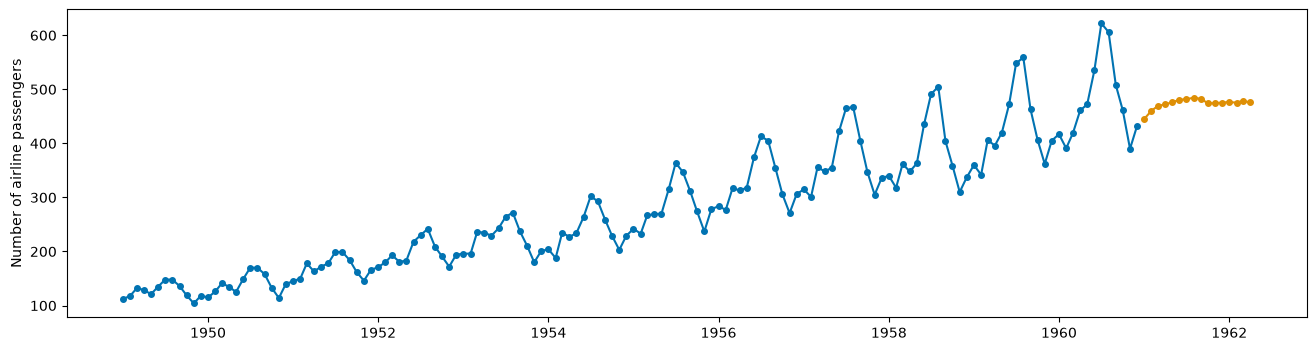

In [6]:
from sktime.utils.plotting import plot_series

plot_series(y, y_pred)

where are weights here?

given in `model_path`, can be:

* `huggingface` model string - uses HF backend then (default)
* local path in folder
* `None` - full tuning from pristine if `fit_strategy="full"`

**Fine-Tuning**

works via providing fine-tuning config.

Same interface - fine-tunes on input data!

In [7]:
forecaster = TinyTimeMixerForecaster(
    model_path="ibm-research/ttm-r3",  # TTM R3: patch sizes can be adapted to short contexts
    config={
        "context_length": 32,
        "trend_patch_length": 8,
        "trend_patch_stride": 8,
        "prediction_length": pred_len,
    },
    training_args={
        "num_train_epochs": 100,
        "output_dir": "test_output",
        "per_device_train_batch_size": 32,
        "report_to": "none",
        "learning_rate": 1e-2,
    },
)
forecaster.fit(y, fh=list(range(1, pred_len+1)))
y_pred = forecaster.predict()

Loading weights:   0%|          | 0/466 [00:00<?, ?it/s]

[transformers] TinyTimeMixerForDecomposedPrediction LOAD REPORT from: ibm-research/ttm-r3
Key                                                                                                                                  | Status     |                                                                                           
-------------------------------------------------------------------------------------------------------------------------------------+------------+-------------------------------------------------------------------------------------------
trend_forecaster.backbone.encoder.patcher.projectors.3.bias                                                                          | UNEXPECTED |                                                                                           
trend_forecaster.backbone.encoder.patcher.projectors.3.weight                                                                        | UNEXPECTED |                                              

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

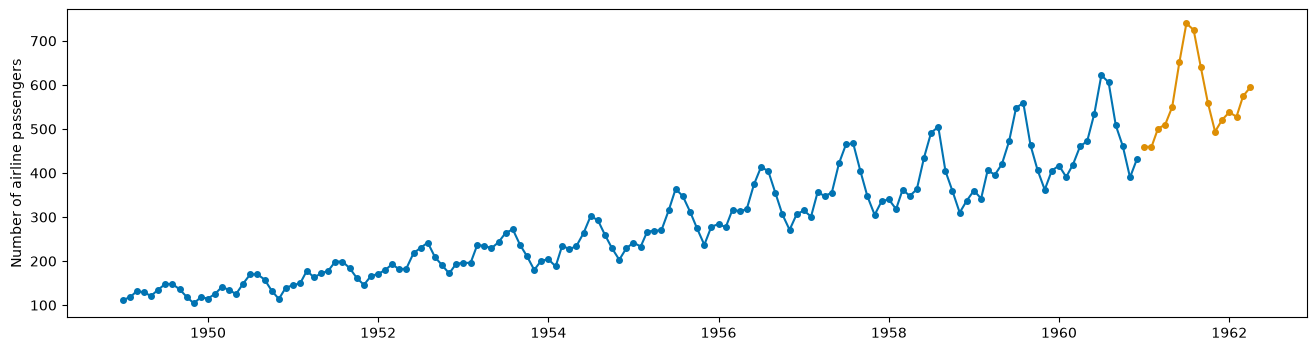

In [8]:
plot_series(y, y_pred)

#### TimesFM

- **Research Paper:** [A Decoder-Only Foundation Model for Time-Series Forecasting](https://arxiv.org/abs/2310.10688)
- **Official Code:** [google-research/timesfm](https://github.com/google-research/timesfm)

**Zero-Shot Forecasting**

In [9]:
from sktime.forecasting.timesfm2 import TimesFM2Forecaster

# default weights: TimesFM 2.5 (200M parameters), "google/timesfm-2.5-200m-transformers"
forecaster = TimesFM2Forecaster()

In [10]:
forecaster.fit(y, fh=list(range(1, pred_len+1)))
y_pred = forecaster.predict()

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

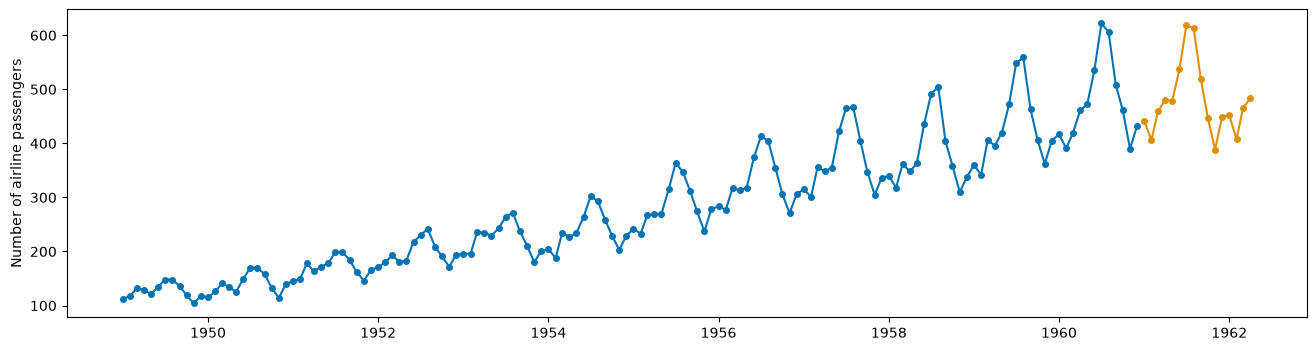

In [11]:
plot_series(y, y_pred)

**TimesFM 3** - the newest TimesFM (2026)

- **Blog post:** [TimesFM 3: a zero-shot foundation model for multivariate forecasting](https://research.google/blog/timesfm-3-a-zero-shot-foundation-model-for-multivariate-forecasting/)
- **Official Code:** [google-research/timesfm](https://github.com/google-research/timesfm)

New compared to TimesFM 2.5: native **multivariate** forecasting and **covariates** (past-only and known-future `X`),
quantile forecasts out of the box. Same `sktime` interface.

⚠️ the pretrained weights are under a **non-commercial license** - `sktime` makes you accept it explicitly.

In [2]:
from sktime.forecasting.timesfm3 import TimesFM3Forecaster

TimesFM3Forecaster.print_license()

TimesFM 3.0 pretrained weights are distributed under the timesfm-non-commercial-license-v1.0, which restricts use to non-commercial, non-production scenarios.
Full license text: https://huggingface.co/google/timesfm-3.0-pytorch/blob/main/LICENSE


(<Figure size 1600x400 with 1 Axes>,
 <Axes: ylabel='Number of airline passengers'>)

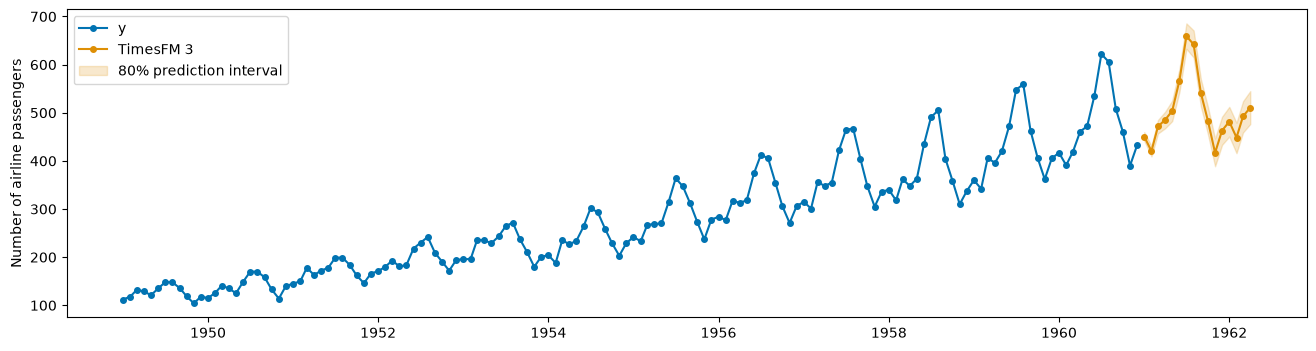

In [13]:
timesfm3 = TimesFM3Forecaster(license_accepted=True)

timesfm3.fit(y, fh=list(range(1, pred_len + 1)))
y_pred = timesfm3.predict()
y_pred_int = timesfm3.predict_interval(coverage=0.8)  # probabilistic forecasts, no extra work

plot_series(y, y_pred, labels=["y", "TimesFM 3"], pred_interval=y_pred_int)

Hold out the last `pred_len` months and compare the FMs from above with a seasonal naive baseline - all zero-shot, same API.

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

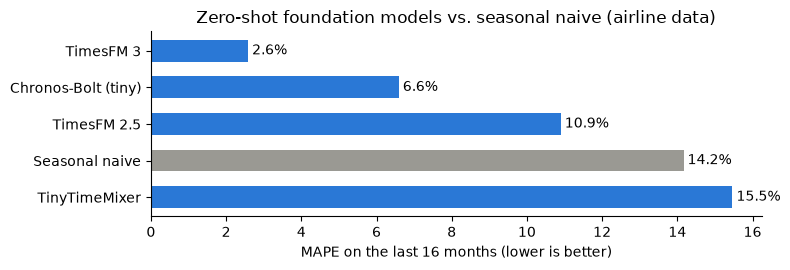

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from sktime.forecasting.chronos import ChronosForecaster
from sktime.forecasting.naive import NaiveForecaster
from sktime.performance_metrics.forecasting import mean_absolute_percentage_error
from sktime.split import temporal_train_test_split

y_train, y_test = temporal_train_test_split(y, test_size=pred_len)
fh = list(range(1, pred_len + 1))

contenders = {
    "Seasonal naive": NaiveForecaster(strategy="last", sp=12),
    "TinyTimeMixer": TinyTimeMixerForecaster(),
    "Chronos-Bolt (tiny)": ChronosForecaster("amazon/chronos-bolt-tiny"),
    "TimesFM 2.5": TimesFM2Forecaster(),
    "TimesFM 3": TimesFM3Forecaster(license_accepted=True),
}
mape = {}
for name, model in contenders.items():
    model.fit(y_train, fh=fh)
    mape[name] = mean_absolute_percentage_error(y_test, model.predict())

mape = pd.Series(mape).sort_values(ascending=False) * 100

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(mape.index, mape.values,
        color=["#9a9993" if n == "Seasonal naive" else "#2a78d6" for n in mape.index], height=0.6)
for i, v in enumerate(mape.values):
    ax.text(v, i, f" {v:.1f}%", va="center")
ax.set_xlabel(f"MAPE on the last {pred_len} months (lower is better)")
ax.set_title("Zero-shot foundation models vs. seasonal naive (airline data)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### managing model code - `sktime` forks, source install, pypi

**Why:** FM code is often hard to install - where does the model code come from in `sktime`?

typical dependency set of an open FM package

```
[project]
...
dependencies = [
  "torch>=2.1",
  "lightning>=2.0",
  "gluonts~=0.14.3",
  "numpy~=1.26.0",
  "scipy~=1.11.3",
  "einops==0.7.*",
  "jaxtyping~=0.2.24",
  "python-dotenv==1.0.0",
  "hydra-core==1.3",
  ...,
]
```

**`sktime` forks typically more stable, trustworthy, and reliable than official sources!**

* optimized dependency management
    * often very strict dep requirements - can be impossible to satisfy!
    * stability via `sktime` deprecation management
* often, no (trustworthy) pypi release available
    * source install is unstable, not suitable for deployment
    * model code may not be on pypi as package
    * non-affiliated people upload unofficial releases - **possible supply chain attacks!**
    * `sktime` is "trusted" package managed by known people & orgs
* license stability
    * stealth license changes even by commercial actors!
    * licenses remain explicit and stable, deprecation management

Default: forked code in [`sktime/libs`](https://github.com/sktime/sktime/tree/main/sktime/libs), license attached with the official code is kept as is and clearly visible.

Source installation can be selected via `use_source_package` parameter

Example, to use `TinyTimeMixer` from source package:

1. install from source

In [15]:
# e.g., to install the 0.2.3 version of granite-tsfm (TinyTimeMixer)
# !pip install git+https://github.com/ibm-granite/granite-tsfm.git@v0.2.3 --quiet

2. set the `use_source_package` flag to `True`

In [16]:
forecaster = TinyTimeMixerForecaster(
    use_source_package=True,
)

**What we learnt so far**

* many foundation models behind one `fit` / `predict` API - zero-shot is just `fit` + `predict`
* weights from Hugging Face or a local path; stable model code via `sktime` forks
* hierarchical and probabilistic forecasts work for FMs via broadcasting and composition

**Next:** adapting a foundation model's weights to your own data.

<a id="fm-finetune"></a>
## 3. Fine-tuning foundation models on your data

**Now:** `pretrain` on a foundation model with loaded weights **is fine-tuning** - it continues training the provider's weights on your data.

Recap from the deep learning notebook: `pretrain` learns from *other*, related time series.
For a foundation model this means: start from the provider's weights, **continue training on your own collection of related series**,
then `fit` / `predict` on the series you care about.

```
provider weights ──pretrain(your related series)──► adapted weights ──fit(target)──► predict
       └────────────────── zero-shot skips the pretrain step ───────────────────┘
```

Typical use case: **cold start** - new products / stores / regions with little history, but many related series with long history.

| Model (`sktime` estimator) | `pretrain`? | what gets trained | practical notes |
|---|---|---|---|
| TinyTimeMixer (`TinyTimeMixerForecaster`) | ✅ | `fit_strategy`: `"zero-shot"` (nothing), `"minimal"` (only re-initialised layers, e.g. a new head), `"full"` (all weights) | ~1M params, fine-tunes on a laptop CPU in seconds; context / horizon fixed by the checkpoint `revision` |
| TimesFM 2 / 2.5 (`TimesFM2Forecaster`) | ✅ | full fine-tuning, or parameter-efficient **LoRA** via `peft_config`; optional quantization | 200M params - GPU (or LoRA) recommended |
| Time-MoE (`TimeMoEForecaster`) | ✅ | fine-tune a checkpoint, or train from scratch (`model_path=None`) | pins `transformers<=4.40.1` - needs its own environment |
| Sundial (`SundialForecaster`) | ✅ | fine-tune | pins `transformers~=4.40` |
| Toto (`TotoForecaster`) | ✅ | fine-tune | `toto-ts` package |
| Lag-Llama (`LagLlamaForecaster`) | ✅ | fine-tune (lightning) | calling `pretrain` again re-runs fine-tuning on the new data |
| Chronos, Chronos-2, Moirai, TimesFM 3, TiRex, ... | ❌ | zero-shot only (in `sktime`) | use as-is; compose for intervals, hierarchies etc. |

Things to keep in mind:

* **what gets updated** differs per model: nothing, a new head, low-rank adapters (LoRA), or all weights - check the docstring
* **checkpoint shapes are fixed**: context length, horizon and patch size come from the checkpoint; series shorter than context + horizon give few or no training windows
* **compute**: small models (TTM) fine-tune on a CPU; 100M+ parameter models (TimesFM 2.5, Toto, Time-MoE) want a GPU or LoRA
* **overfitting / forgetting**: few steps, small learning rate, validation split - and always compare against the zero-shot model
* **leakage**: pretrain only on data from *before* the test period
* **licenses**: fine-tuned weights are derived from the provider's weights - the weight license still applies (e.g., TimesFM 3: non-commercial)

Data: synthetic monthly tourism trips, 28 series (travel purpose x state), 228 months.

* pretend all **Business** travel series are *new*: only the last 5 years of history are available
* the other purposes (Holiday, Visiting, Other) are the *related* series we pretrain on - only data up to the cutoff, no leakage
* forecast the last 6 months of the new series and compare

**Steps:** split → TTM zero-shot → fine-tune TTM on the related series (`pretrain`) → `fit` on the new series → compare with baselines and TimesFM 2.5 zero-shot

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sktime.split import temporal_train_test_split

df_tourism = pd.read_csv("data/monthly_tourism_synthetic.csv")
df_tourism["Month"] = pd.PeriodIndex(df_tourism["Month"], freq="M")
y_tourism = df_tourism.groupby(["Purpose", "State", "Month"])[["Trips"]].sum()

HORIZON = 6               # forecast the last 6 months
HISTORY = 60              # the "new" series have 5 years of history
NEW_PURPOSE = "Business"  # pretend these series are new

y_train, y_test = temporal_train_test_split(y_tourism, test_size=HORIZON)

# related series: the other travel purposes, training part only
y_related = y_train.drop(index=NEW_PURPOSE, level="Purpose")

# new series: short history for fitting, last 6 months for evaluation
y_new_train = y_train.loc[[NEW_PURPOSE]].groupby(level=["Purpose", "State"]).tail(HISTORY)
y_new_test = y_test.loc[[NEW_PURPOSE]]

n_related = y_related.index.droplevel(-1).nunique()
n_new = y_new_train.index.droplevel(-1).nunique()
print(f"related series: {n_related}, new series: {n_new} with {HISTORY} months of history")

related series: 21, new series: 7 with 60 months of history


In [24]:
from sktime.forecasting.ttm import TinyTimeMixerForecaster

# TTM checkpoint with a short context: 52 months in, up to 16 months out
TTM_CHECKPOINT = dict(
    model_path="ibm-granite/granite-timeseries-ttm-r2",
    revision="52-16-ft-r2.1",
)
fh = list(range(1, HORIZON + 1))

ttm_zero_shot = TinyTimeMixerForecaster(**TTM_CHECKPOINT, fit_strategy="zero-shot")
ttm_zero_shot.fit(y_new_train, fh=fh)
y_pred_zero_shot = ttm_zero_shot.predict()

Loading weights:   0%|          | 0/267 [00:00<?, ?it/s]

In [25]:
ttm_pretrained = TinyTimeMixerForecaster(
    **TTM_CHECKPOINT,
    fit_strategy="full",  # update all weights (~1M parameters)
    training_args={
        "max_steps": 100,
        "per_device_train_batch_size": 32,
        "learning_rate": 1e-3,
        "output_dir": "test_output",
        "report_to": "none",
        "save_strategy": "no",  # no intermediate checkpoints on disk
    },
)
ttm_pretrained.pretrain(y_related)
print(f"State: {ttm_pretrained.state}")

ttm_pretrained.fit(y_new_train, fh=fh)
y_pred_pretrained = ttm_pretrained.predict()
print(f"State: {ttm_pretrained.state}")

Loading weights:   0%|          | 0/267 [00:00<?, ?it/s]

Step,Training Loss


State: pretrained


Step,Training Loss


Step,Training Loss


Step,Training Loss


Step,Training Loss


Step,Training Loss


Step,Training Loss


Step,Training Loss


State: fitted


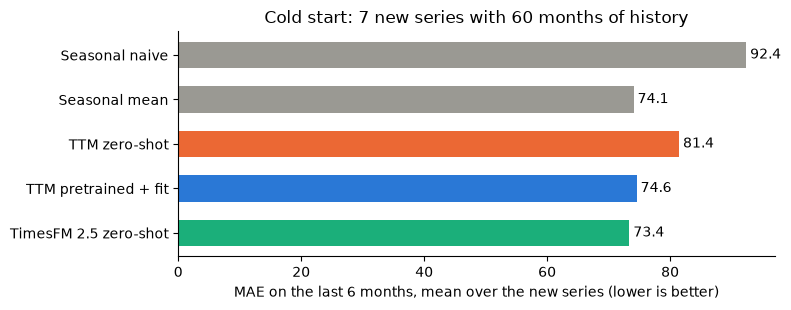

In [26]:
from sktime.forecasting.naive import NaiveForecaster
from sktime.performance_metrics.forecasting import MeanAbsoluteError

predictions = {
    "Seasonal naive": NaiveForecaster(strategy="last", sp=12).fit(y_new_train, fh=fh).predict(),
    "Seasonal mean": NaiveForecaster(strategy="mean", sp=12).fit(y_new_train, fh=fh).predict(),
    "TTM zero-shot": y_pred_zero_shot,
    "TTM pretrained + fit": y_pred_pretrained,
    # a much larger FM, zero-shot - for comparison
    "TimesFM 2.5 zero-shot": TimesFM2Forecaster().fit(y_new_train, fh=fh).predict(),
}

mae = MeanAbsoluteError(multilevel="uniform_average")  # MAE per series, averaged over series
scores = pd.Series({name: mae(y_new_test, y_pred) for name, y_pred in predictions.items()})

colors = {
    "Seasonal naive": "#9a9993",
    "Seasonal mean": "#9a9993",
    "TTM zero-shot": "#eb6834",
    "TTM pretrained + fit": "#2a78d6",
    "TimesFM 2.5 zero-shot": "#1baf7a",
}
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(scores.index, scores.values, color=[colors[n] for n in scores.index], height=0.6)
for i, v in enumerate(scores.values):
    ax.text(v, i, f" {v:.1f}", va="center")
ax.invert_yaxis()
ax.set_xlabel("MAE on the last 6 months, mean over the new series (lower is better)")
ax.set_title(f"Cold start: {n_new} new series with {HISTORY} months of history")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

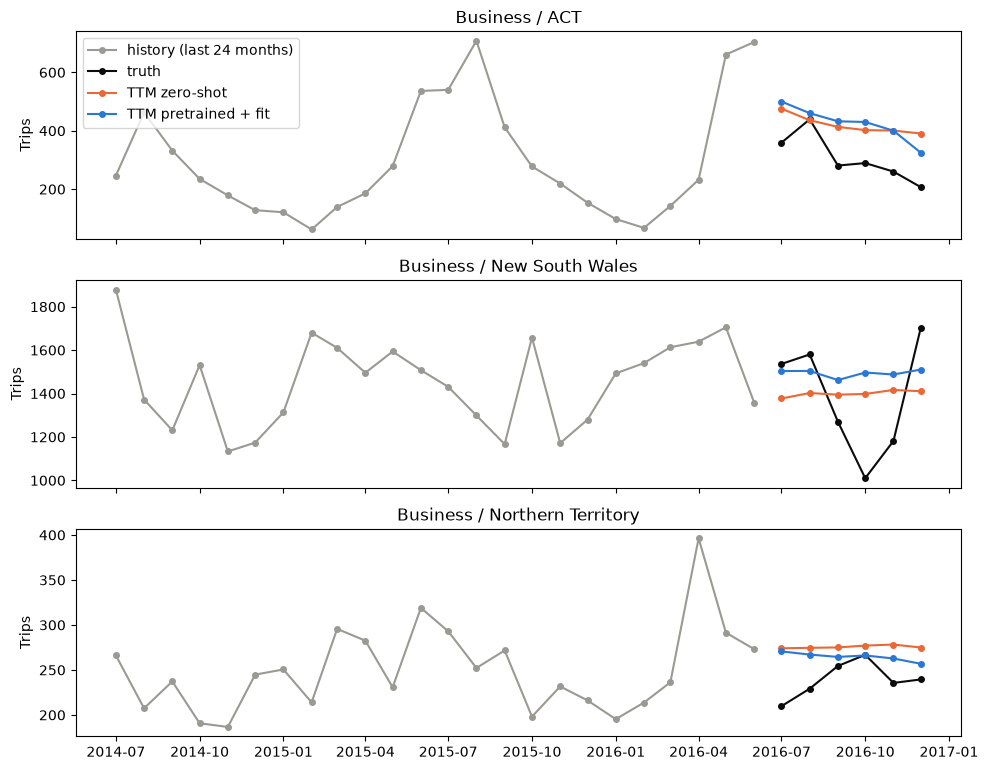

In [27]:
# forecasts for a few of the new series
states_to_plot = y_new_test.index.get_level_values("State").unique()[:3]
fig, axes = plt.subplots(len(states_to_plot), 1, figsize=(10, 2.6 * len(states_to_plot)), sharex=True)

for ax, state in zip(axes, states_to_plot):
    series_id = (NEW_PURPOSE, state)
    plot_series(
        y_new_train.loc[series_id].iloc[-24:],
        y_new_test.loc[series_id],
        y_pred_zero_shot.loc[series_id],
        y_pred_pretrained.loc[series_id],
        labels=["history (last 24 months)", "truth", "TTM zero-shot", "TTM pretrained + fit"],
        colors=["#9a9993", "#0b0b0b", "#eb6834", "#2a78d6"],
        ax=ax,
    )
    ax.set_title(f"{NEW_PURPOSE} / {state}")
    ax.set_ylabel("Trips")
    if ax is not axes[0]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

Results from separate runs (`sktime` 1.3.0, TTM `52-16-ft-r2.1`, 100 training steps; mean MAE over the held-out series, lower is better):

| held-out ("new") purpose | seasonal naive | seasonal mean | TTM zero-shot | TTM fine-tuned on new series only | TTM pretrained + fit |
|---|---|---|---|---|---|
| Business (the run above) | 92.4 | **74.1** | 81.4 | 80.3 | 74.6 |
| Holiday | 186.5 | **126.6** | 254.3 | 286.9 | 243.6 |
| Visiting | 119.2 | **75.1** | 156.0 | 189.2 | 149.9 |
| Other | 26.7 | 18.0 | 19.3 | 17.6 | **17.3** |

**What we learnt:**

* pretraining on related series beats zero-shot **and** fine-tuning on the short history alone - in every fold
* with a long history (10 years instead of 5), fine-tuning on the new series alone catches up: pretraining matters most for **cold start**
* ... and on this (synthetic, very regular) data the seasonal mean is still best in 3 of 4 folds: **benchmark on your own data!**
* model choice is the other lever: above, the much larger TimesFM 2.5 *zero-shot* is on par with the pretrained (tiny) TTM

Large FMs are usually not fine-tuned fully: **LoRA** trains small low-rank adapter matrices next to the frozen weights.
In `sktime` this is one extra argument, `peft_config` (requires the `peft` package) - same `pretrain` / `fit` / `predict` workflow:

```python
from peft import LoraConfig
from sktime.forecasting.timesfm2 import TimesFM2Forecaster

timesfm_lora = TimesFM2Forecaster(
    peft_config=LoraConfig(r=8, lora_alpha=32, target_modules=["q_proj", "v_proj"], lora_dropout=0.01),
    training_args={"max_steps": 500, "per_device_train_batch_size": 16, "learning_rate": 1e-4,
                   "output_dir": "test_output", "report_to": "none"},
)
timesfm_lora.pretrain(y_related)
timesfm_lora.fit(y_new_train)
y_pred = timesfm_lora.predict(fh=fh)
```

<a id="fm-legal"></a>
## 4. Legal side and methodology

**Now:** what licenses mean for using FMs - and the key question: should I use foundation models now?

### FM on the legal side

FM are "multi-component" technology - API, weights, model code, data, ...

* different artefacts under different licenses
* **artefacts** and **usage** may be under different licenses
* **licenses can be unstable!** stealth changes possible on HF or source installs
* gated APIs usually subject to additional Terms and Conditions (which can change)

legislators and regulators tend to be confused about these...

<img src="./imgs/fm-license.png" style="width: 100%; max-width: 600px;">

`sktime` tries to minimize license issues but cannot entirely remove them!

* "frozen" code with version management
* forks branch off at permissive licenses (prior stealth change to restrictive)
    * view licenses in `libs` folder

Caveat: if using weights, inspect weights licenses and T&C

### methodology - so should I use foundation models now?

FM are promising category of models, but:

* many competing FM!
* every FM is 1st in some benchmark...
* may or may not be useful for your data!

General advice same as for other model:

**test and benchmark on your own data!**

**and compare pros/cons w.r.t. requirements for your use case!**

(e.g., simplicity/interpretability, compute/memory, local/cloud, security)

<a id="fm-recap"></a>
## 5. Recap - what we learnt

* **pre-trained DL models** with zero-shot, few-shot and/or fine-tune capabilities
* varying degrees of openness - fully open, semi-open, gated
* hard to use directly, install, deploy, test - lock-in & lock-out dynamics
* `pretrain` adapts FM weights to **your own related series** - most useful for cold start; strategies differ per model (head only, LoRA, full)
* newest models (e.g., TimesFM 3) plug into the same interface - but check the **weight license** before use

`sktime` unified API makes use and comparison of multiple FM easy!

* handling code, weights, parameters under the hood; zero-shot and fine-tuning
* different weights backends - local, weight hubs, train from scratch
* FM vendor mini-packages with stable code, interfaces, licenses

**`sktime` is currently only framework that does this! Only neutral framework!**

contribute if you find this useful.

**best practice: always try and test on your own data!** FM or not.